# Análise Exploratória de Dados (EDA) — Roubo de Veículos no MRJ (2003–2022)
**Autor:** Caio Silva Lopes  
**Curso:** Bacharelado em Sistemas de Informação — 6º Período (Semestre 2026.2)  
**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python)  
**Repositório:** [https://github.com/CaioSIlvaLopes/LINGUAGENS-DE-PROGRAMA-O-Projeto-Pr-tico-G2.git](https://github.com/CaioSIlvaLopes/LINGUAGENS-DE-PROGRAMA-O-Projeto-Pr-tico-G2.git)  
**Fonte Primária:** DATA.RIO / Instituto de Segurança Pública (ISP-RJ) — Tabela 2306

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregamento do dataset processado e validado pelo pipeline src/etl.py
df = pd.read_csv('../data/processed/roubo_veiculos_mrj_2003_2022.csv')
print(df.to_string(index=False))

 ano  total_jan_abr  dif_absoluta  dif_percentual    populacao  taxa_100k  media_mensal
2003           8558           NaN             NaN 5.865737e+06 145.898110       2139.50
2004           7680        -878.0      -10.259406 6.027371e+06 127.418731       1920.00
2005           8744        1064.0       13.854167 6.073353e+06 143.973200       2186.00
2006           8215        -529.0       -6.049863 6.119685e+06 134.238945       2053.75
2007           7996        -219.0       -2.665855 6.166370e+06 129.671101       1999.00
2008           6056       -1940.0      -24.262131 6.213412e+06  97.466581       1514.00
2009           5896        -160.0       -2.642008 6.260812e+06  94.173084       1474.00
2010           4577       -1319.0      -22.371099 6.305800e+06  72.583968       1144.25
2011           3140       -1437.0      -31.396111 6.352662e+06  49.428096        785.00
2012           3774         634.0       20.191083 6.381751e+06  59.137373        943.50
2013           3632        -142.

In [2]:
# 2. Estatísticas Descritivas (Contagem, Média, Mediana, Mínimo, Máximo e Desvio Padrão)
cols_numericas = ['total_jan_abr', 'dif_absoluta', 'dif_percentual', 'populacao', 'taxa_100k', 'media_mensal']
stats = df[cols_numericas].agg(['count', 'mean', 'median', 'min', 'max', 'std']).T
print('Estatísticas Descritivas da Série Histórica (2003–2022):')
print(stats.round(2).to_string())

Estatísticas Descritivas da Série Histórica (2003–2022):
                count        mean      median         min         max        std
total_jan_abr    20.0     6216.30     5976.00     3140.00     9679.00    1982.21
dif_absoluta     19.0     -223.53     -160.00    -2684.00     2331.00    1283.63
dif_percentual   19.0       -1.50       -2.67      -31.40       37.75      20.77
populacao        20.0  6391547.44  6400913.35  5865737.42  6802575.57  267889.48
taxa_100k        20.0       97.90       95.63       49.43      145.90      33.00
media_mensal     20.0     1554.08     1494.00      785.00     2419.75     495.55


In [3]:
# 3. Agrupamento por Ciclos Históricos Plurianuais (RQ1 e RQ2)
df['ciclo_historico'] = pd.cut(
    df['ano'],
    bins=[2002, 2007, 2013, 2018, 2022],
    labels=[
        '2003-2007: Patamar Elevado Inicial',
        '2008-2013: Retração Consistente (Ciclo UPP)',
        '2014-2018: Crise Fiscal e Escalada Crítica',
        '2019-2022: Queda Pós-Intervenção e Pandemia'
    ]
)
ciclos = df.groupby('ciclo_historico', observed=False)[['total_jan_abr', 'taxa_100k', 'media_mensal']].agg(['count', 'mean', 'median', 'std']).round(2)
print('Desempenho por Ciclos Históricos de Segurança Pública no MRJ:')
print(ciclos.to_string())

Desempenho por Ciclos Históricos de Segurança Pública no MRJ:
                                            total_jan_abr                           taxa_100k                        media_mensal                          
                                                    count     mean  median      std     count    mean  median    std        count     mean   median     std
ciclo_historico                                                                                                                                            
2003-2007: Patamar Elevado Inicial                      5  8238.60  8215.0   426.88         5  136.24  134.24   8.34            5  2059.65  2053.75  106.72
2008-2013: Retração Consistente (Ciclo UPP)             6  4512.50  4175.5  1225.16         6   71.56   65.86  20.26            6  1128.12  1043.88  306.29
2014-2018: Crise Fiscal e Escalada Crítica              5  7030.20  6304.0  2029.72         5  107.66   97.08  29.86            5  1757.55  1576.00  507.43
20

In [4]:
# 4. Análise de Correlação e Regressão Linear OLS (RQ3: Demografia vs. Criminalidade)
pearson_r = df['populacao'].corr(df['total_jan_abr'], method='pearson')
spearman_r = df['populacao'].corr(df['total_jan_abr'], method='spearman')
pearson_taxa = df['populacao'].corr(df['taxa_100k'], method='pearson')
slope, intercept = np.polyfit(df['populacao'] / 1e6, df['total_jan_abr'], 1)

print(f'Correlação de Pearson (População vs Total Jan-Abr): {pearson_r:.4f}')
print(f'Correlação de Spearman (População vs Total Jan-Abr): {spearman_r:.4f}')
print(f'Correlação de Pearson (População vs Taxa por 100k): {pearson_taxa:.4f}')
print(f'Equação OLS (RQ3): Total_Roubos = {slope:.2f} * Pop_Milhoes + {intercept:.2f} (R² = {pearson_r**2:.4f})')

Correlação de Pearson (População vs Total Jan-Abr): -0.3742
Correlação de Spearman (População vs Total Jan-Abr): -0.3308
Correlação de Pearson (População vs Taxa por 100k): -0.4911
Equação OLS (RQ3): Total_Roubos = -2768.91 * Pop_Milhoes + 23913.91 (R² = 0.1400)


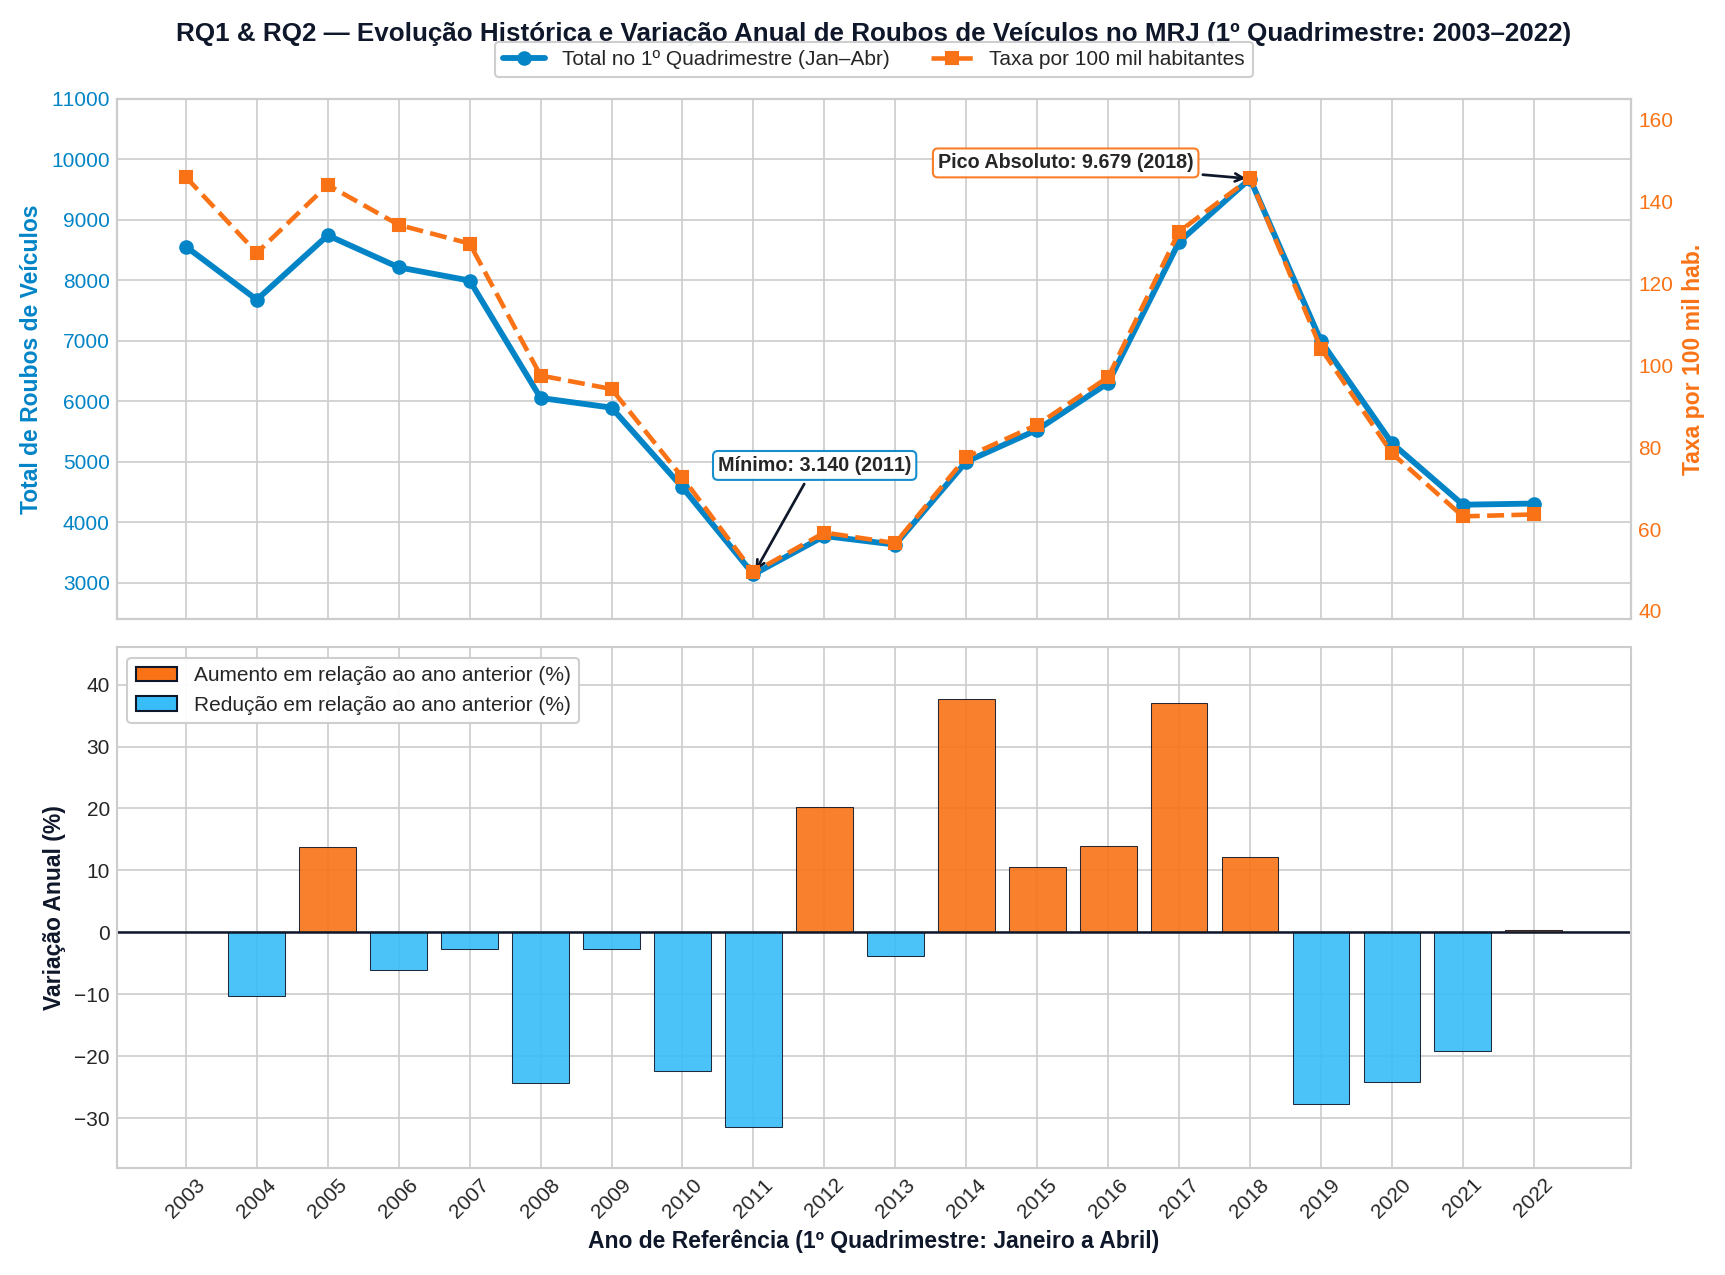

In [5]:
# 5. Visualização Analítica 1: Série Histórica (RQ1) e Choques Anuais de Variação (RQ2)
from IPython.display import Image, display
display(Image(filename='../docs/assets/analise_roubo_veiculos_rj.png'))

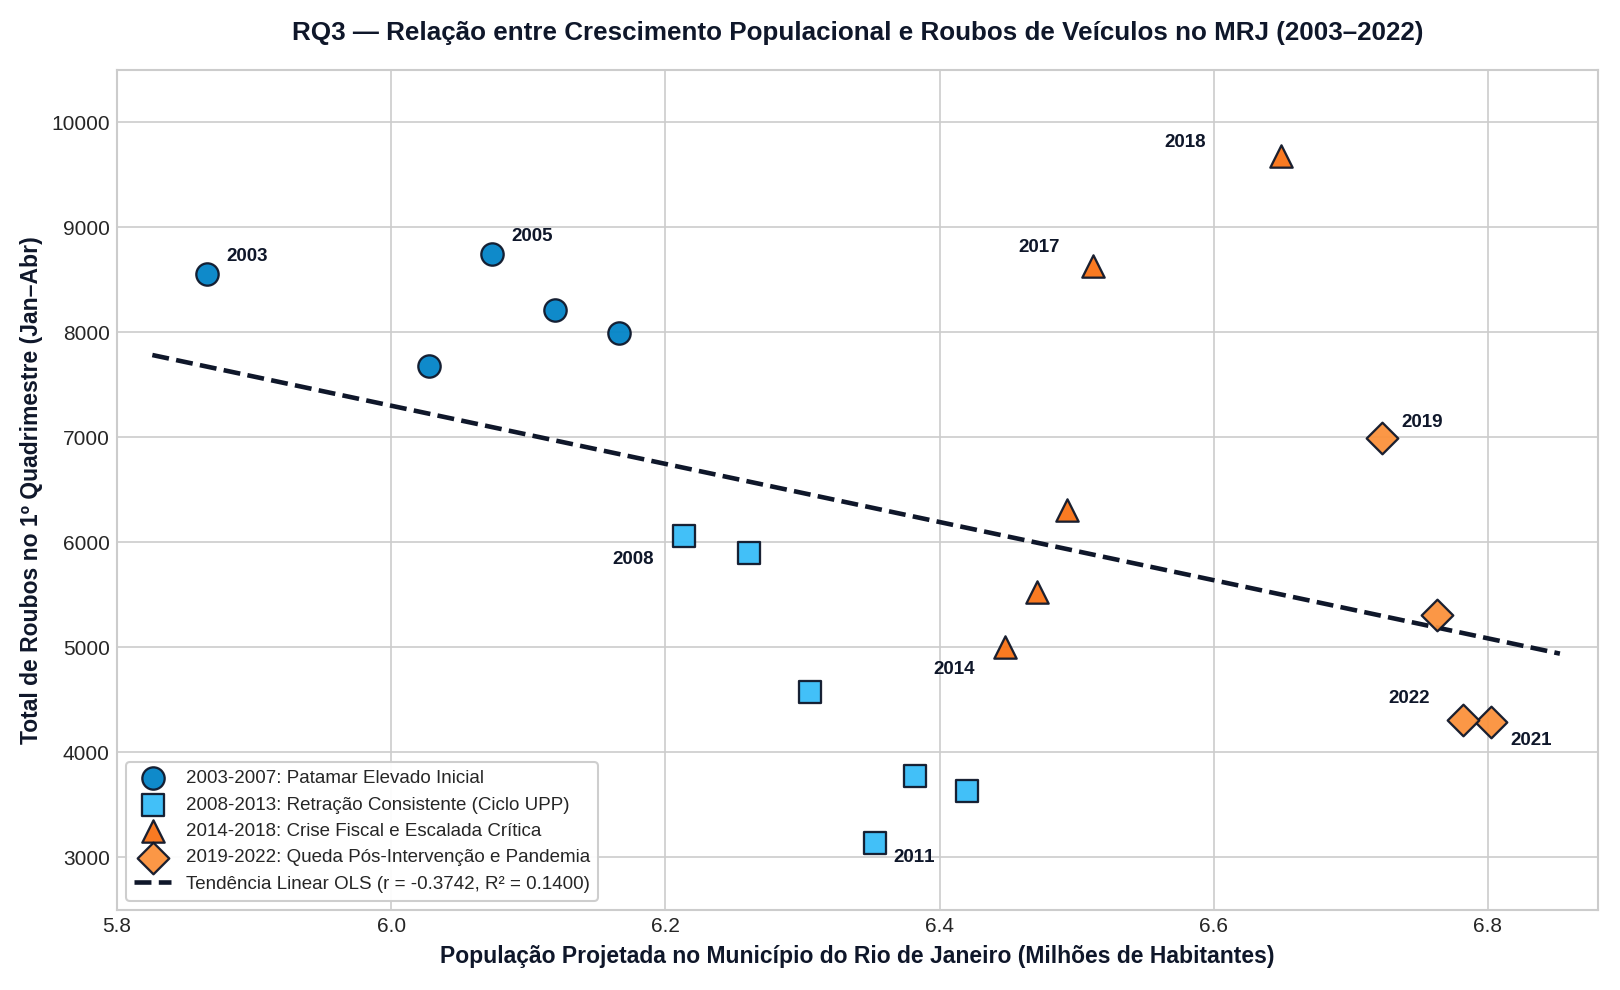

In [6]:
# 6. Visualização Analítica 2: Dispersão População vs. Roubos com Regressão OLS (RQ3)
display(Image(filename='../docs/assets/dispersao_populacao_roubos_rj.png'))